# Project Title
---

## Introduction 
__Introduction to the topic__ 

    ...
This project analyses 261,507 Olympic athlete records from 1896 to 2016, covering 66 sports and 757 events.
It looks at how likely an athlete is to win a medal (the win rate) and how that changes by sport, season, sex, age, height and weight.
The goal is to show that medal odds are not equal across sports, so results should not be compared without context.
---

## Problem Statement

Across 261,507 Olympic athlete records from 1896 to 2016, win rate ranges from 4.9% in Alpine Skiing to 28.7% in Hockey among sports with more than 5,000 records, a nearly 6x gap. Judging sports on results alone, without accounting for this gap, can mislead decisions on where to develop athletes.


## Objectives:
__Questions that will guide the analysis to solve the problem__

- What is the overall win rate across all athlete records, 1896-2016, and how many sports and events does it cover?
- How do the 18 sports with 5,000+ records rank by win rate, from highest to lowest?
- What is the win rate in Summer vs Winter Games, and how large is the gap?
- How does win rate differ across age, height and weight groups?
- Do sex, season, age, height and weight change which medal (Gold, Silver or Bronze) an athlete wins?


---

## Exploratory Data Analysis (EDA):

### Data Info:
__Getting the data and exploring it (includes descriptive statistics)__

In [1]:
import pandas as pd
df = pd.read_csv('athlete_events.csv',na_values='Na')

In [2]:
df.shape

(271116, 15)

In [3]:
df.dtypes

ID          int64
Name          str
Sex           str
Age       float64
Height    float64
Weight    float64
Team          str
NOC           str
Games         str
Year        int64
Season        str
City          str
Sport         str
Event         str
Medal         str
dtype: object

In [4]:
df.sample(5)

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
158675,79660,Andrey Anatolyevich Mikhnevich,M,36.0,202.0,140.0,Belarus,BLR,2012 Summer,2012,Summer,London,Athletics,Athletics Men's Shot Put,NaN
64980,33252,mile Ess,M,20.0,173.0,76.0,Switzerland,SUI,1952 Summer,1952,Summer,Helsinki,Rowing,Rowing Men's Coxed Fours,Silver
164023,82328,Eva Mortensen,F,18.0,171.0,55.0,Denmark,DEN,1988 Summer,1988,Summer,Seoul,Swimming,Swimming Women's 400 metres Freestyle,NaN
113090,57291,Pavel Kantorek,M,34.0,172.0,63.0,Czechoslovakia,TCH,1964 Summer,1964,Summer,Tokyo,Athletics,Athletics Men's Marathon,NaN
9891,5412,Maya Arusi,F,21.0,160.0,49.0,Israel,ISR,2004 Summer,2004,Summer,Athina,Taekwondo,Taekwondo Women's Flyweight,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  str    
 2   Sex     271116 non-null  str    
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  str    
 7   NOC     271116 non-null  str    
 8   Games   271116 non-null  str    
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  str    
 11  City    271116 non-null  str    
 12  Sport   271116 non-null  str    
 13  Event   271116 non-null  str    
 14  Medal   39783 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 56.6 MB


In [6]:
df.isna().sum()

ID             0
Name           0
Sex            0
Age         9474
Height     60171
Weight     62875
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     231333
dtype: int64

In [7]:
df[df['Name'].duplicated(keep=False)].sort_values('Name')

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
215054,107953,Eleonora Margarida Josephina Scmitt,F,16.0,NaN,NaN,Brazil,BRA,1948 Summer,1948,Summer,London,Swimming,Swimming Women's 100 metres Freestyle,NaN
215055,107953,Eleonora Margarida Josephina Scmitt,F,16.0,NaN,NaN,Brazil,BRA,1948 Summer,1948,Summer,London,Swimming,Swimming Women's 4 x 100 metres Freestyle Relay,NaN
51334,26388,Luis ngel Fernando de los Santos Grossi,M,23.0,NaN,NaN,Uruguay,URU,1948 Summer,1948,Summer,London,Cycling,"Cycling Men's Team Pursuit, 4,000 metres",NaN
51335,26388,Luis ngel Fernando de los Santos Grossi,M,27.0,NaN,NaN,Uruguay,URU,1952 Summer,1952,Summer,Helsinki,Cycling,"Cycling Men's Road Race, Individual",NaN
51336,26388,Luis ngel Fernando de los Santos Grossi,M,27.0,NaN,NaN,Uruguay,URU,1952 Summer,1952,Summer,Helsinki,Cycling,"Cycling Men's Road Race, Team",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10589,5787,zer Atei,M,25.0,180.0,72.0,Turkey,TUR,1968 Winter,1968,Winter,Grenoble,Alpine Skiing,Alpine Skiing Men's Slalom,NaN
114964,58232,zlem Kaya,F,22.0,165.0,47.0,Turkey,TUR,2012 Summer,2012,Summer,London,Athletics,"Athletics Women's 3,000 metres Steeplechase",NaN
114965,58232,zlem Kaya,F,26.0,165.0,47.0,Turkey,TUR,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,"Athletics Women's 3,000 metres Steeplechase",NaN
102955,52087,zzet nce,M,23.0,172.0,85.0,Turkey,TUR,2004 Summer,2004,Summer,Athina,Weightlifting,Weightlifting Men's Light-Heavyweight,NaN


In [8]:
df.duplicated().sum()

np.int64(1385)

In [9]:
df.isna().sum()

ID             0
Name           0
Sex            0
Age         9474
Height     60171
Weight     62875
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     231333
dtype: int64

### Data Handling: 
__Cleaning, transforming, and combining data__

In [10]:
df = df.dropna(subset=['Age'])

In [11]:
df.isna().sum()

ID             0
Name           0
Sex            0
Age            0
Height     51574
Weight     54263
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     222591
dtype: int64

In [12]:
temp1 = df.groupby(['Sex','Age'])[['Height', 'Weight']].transform('mean').round()


df[['Height', 'Weight']] = df[['Height', 'Weight']].fillna(temp1)

In [13]:
df.isna().sum()

ID             0
Name           0
Sex            0
Age            0
Height       132
Weight       135
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     222591
dtype: int64

In [14]:
df = df.dropna(subset=['Height'])
df = df.dropna(subset=['Weight'])

In [15]:
df.isna().sum()

ID             0
Name           0
Sex            0
Age            0
Height         0
Weight         0
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     222461
dtype: int64

In [16]:
df['Medal'] = df['Medal'].fillna('Lose')

In [17]:
df.isna().sum()

ID        0
Name      0
Sex       0
Age       0
Height    0
Weight    0
Team      0
NOC       0
Games     0
Year      0
Season    0
City      0
Sport     0
Event     0
Medal     0
dtype: int64

In [18]:
 df.to_csv('cleaned_athlete_events.csv')

### Analysis: 
__Answering the objectives through data analysis__



In [19]:
df = pd.read_csv('cleaned_athlete_events.csv')

In [20]:
df['Age_Group'] = pd.cut(df['Age'], bins=[0, 18,25, 30, 40, 50, 100], labels= ['Under 18', '18-25','26-30', '31-40', '41-50', '51+'])

In [21]:
df['Is_Win'] = (df['Medal'] != 'Lose').astype(int)

In [22]:
df['Height_Group'] = pd.cut(df['Height'], bins=[125, 150, 165, 180, 195, 210, 230],
                            labels=['125-150', '151-165', '166-180', '181-195', '196-210', '211-230'])

In [23]:
df['Weight_Group'] = pd.cut(df['Weight'], bins=[25, 50, 65, 80, 95, 110, 140, 220],
                            labels=['25-50', '51-65', '66-80', '81-95', '96-110', '111-140', '141-220'])


Sex
F    0.151696
M    0.148369
Name: Is_Win, dtype: float64


<Axes: xlabel='Sex'>

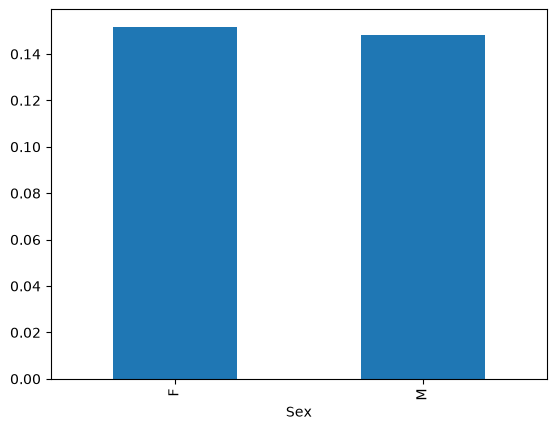

In [24]:
print(df.groupby('Sex')['Is_Win'].mean())
df.groupby('Sex')['Is_Win'].mean().plot(kind = 'bar')

<Axes: title={'center': 'Age group with the highest win rate'}, xlabel='Age_Group'>

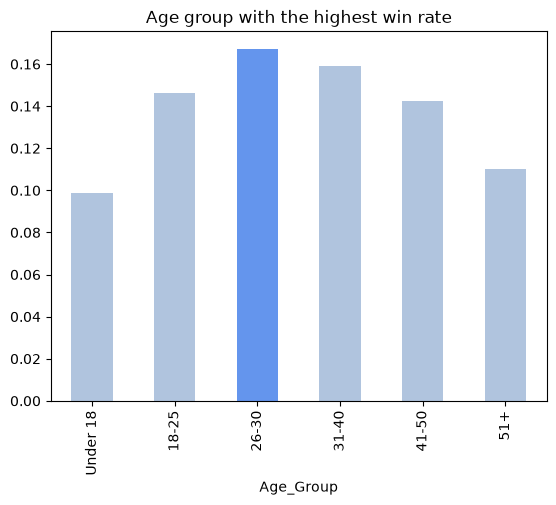

In [25]:
df.groupby('Age_Group')['Is_Win'].mean().plot(kind= 'bar',color =['lightsteelblue','lightsteelblue','cornflowerblue','lightsteelblue','lightsteelblue'],title='Age group with the highest win rate')

<Axes: title={'center': 'Height group with the highest win rate'}, xlabel='Height_Group'>

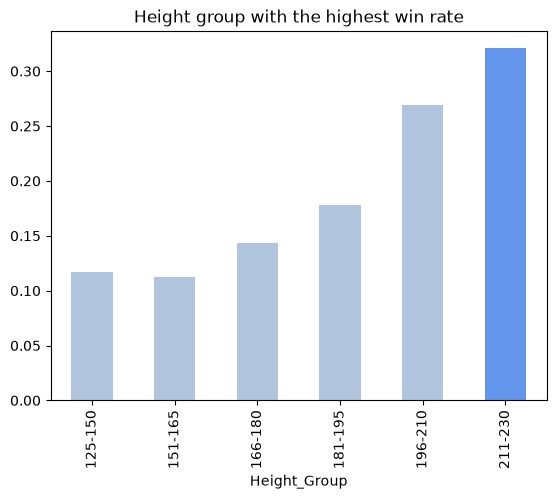

In [26]:
df.groupby('Height_Group')['Is_Win'].mean().plot(kind= 'bar',
                                                 color= ['lightsteelblue','lightsteelblue','lightsteelblue','lightsteelblue','lightsteelblue','cornflowerblue'],
                                                 title='Height group with the highest win rate')

<Axes: title={'center': 'Weight group with the highest win rate'}, xlabel='Weight_Group'>

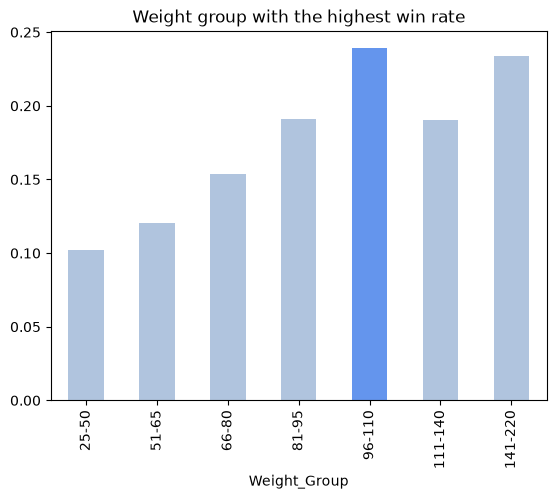

In [27]:
df.groupby('Weight_Group')['Is_Win'].mean().plot(kind= 'bar',
                                                 color= ['lightsteelblue','lightsteelblue','lightsteelblue','lightsteelblue','cornflowerblue'],
                                                 title='Weight group with the highest win rate')

<Axes: title={'center': 'Sports with the lowest win rate.'}, ylabel='Sport'>

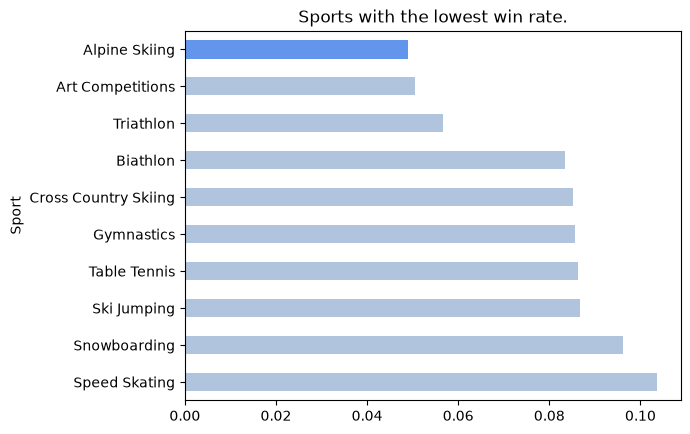

In [28]:
sportmin = df.groupby('Sport').agg(avrgeWin= ('Is_Win','mean'), number=('Is_Win','count'))
#sportmin = sportsss[sportsss['number'] > 5000]

sportmin['avrgeWin'].sort_values(ascending = False).tail(10).plot(kind= 'barh',
                                                       color=['lightsteelblue'] * 9 + ['cornflowerblue'],
                                                       title= 'Sports with the lowest win rate.')

<Axes: title={'center': 'Sports with the highest win rate.'}, ylabel='Sport'>

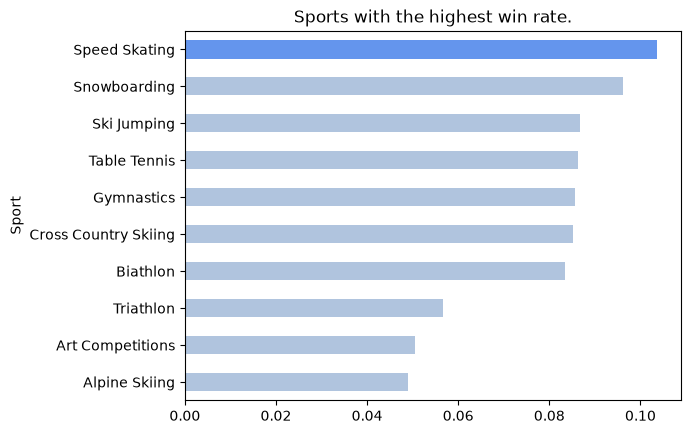

In [29]:
sportmax = df.groupby('Sport').agg(avrgeWin= ('Is_Win','mean'), number=('Is_Win','count'))
#sportmin = sportsss[sportsss['number'] > 5000]

sportmax['avrgeWin'].sort_values(ascending = True).head(10).plot(kind= 'barh',
                                                       color=['lightsteelblue'] * 9 + ['cornflowerblue'],
                                                       title= 'Sports with the highest win rate.')

<Axes: title={'center': 'Sports with the highest win rate and more than 5,000 players.'}, ylabel='Sport'>

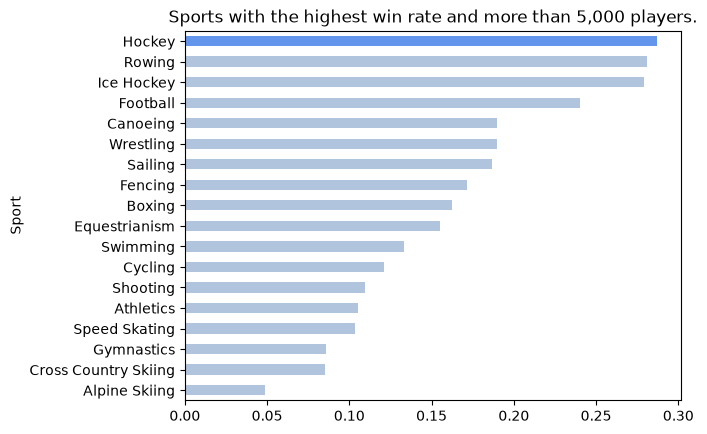

In [30]:
sportsss = df.groupby('Sport').agg(avrgeWin= ('Is_Win','mean'), number=('Is_Win','count'))
sportsss = sportsss[sportsss['number'] > 5000]

sportsss['avrgeWin'].sort_values(ascending = True).plot(kind= 'barh',
                                                       color=['lightsteelblue'] * (len(sportsss)-1 ) + ['cornflowerblue'],
                                                       title= 'Sports with the highest win rate and more than 5,000 players.')

<Axes: title={'center': 'Win Rate: Summer vs Winter'}, xlabel='Season'>

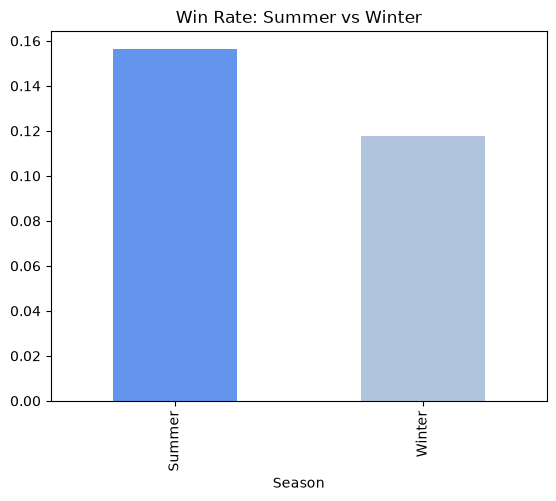

In [31]:
df.groupby('Season')['Is_Win'].mean().plot(
    kind='bar', color=['cornflowerblue','lightsteelblue'], title='Win Rate: Summer vs Winter'
)

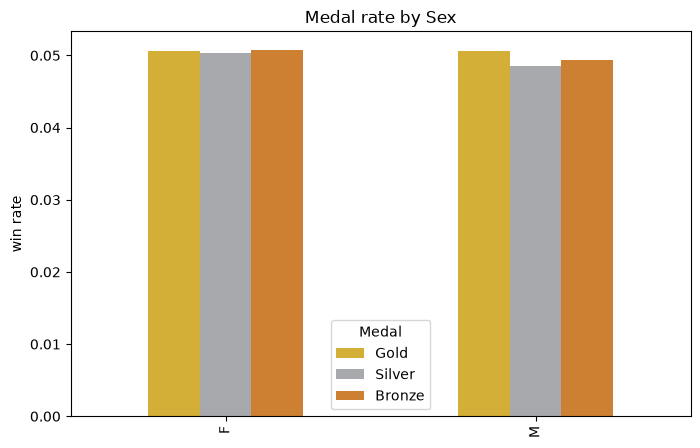

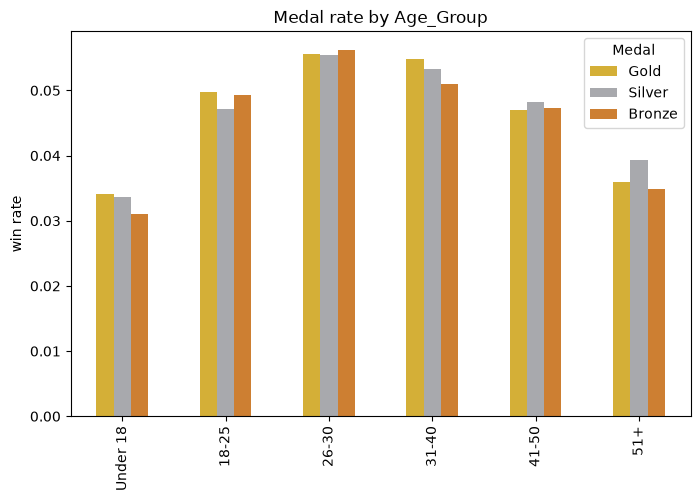

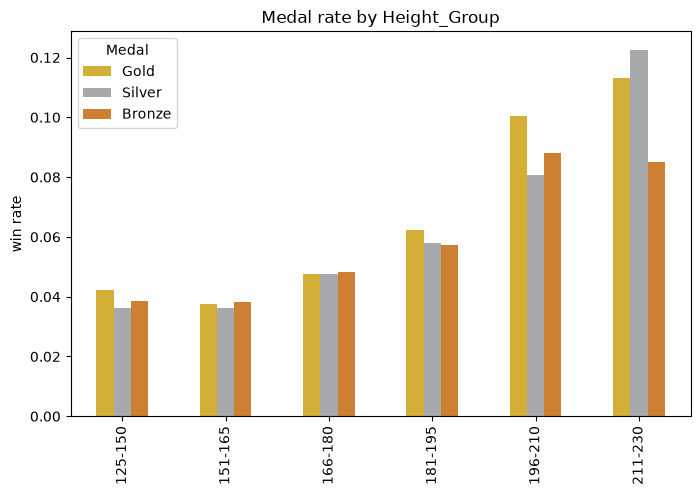

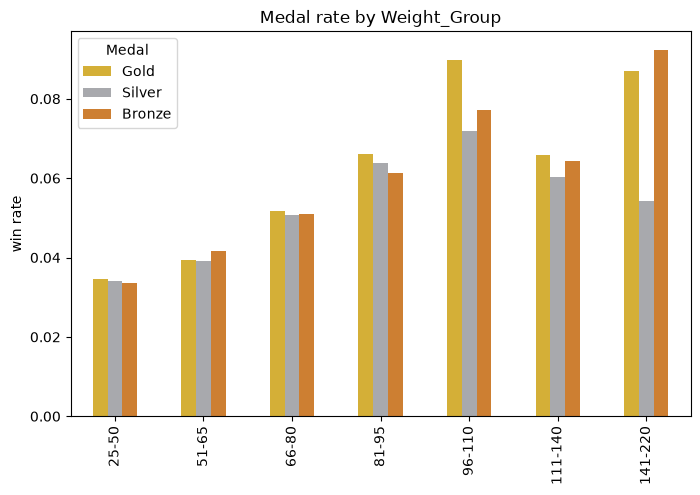

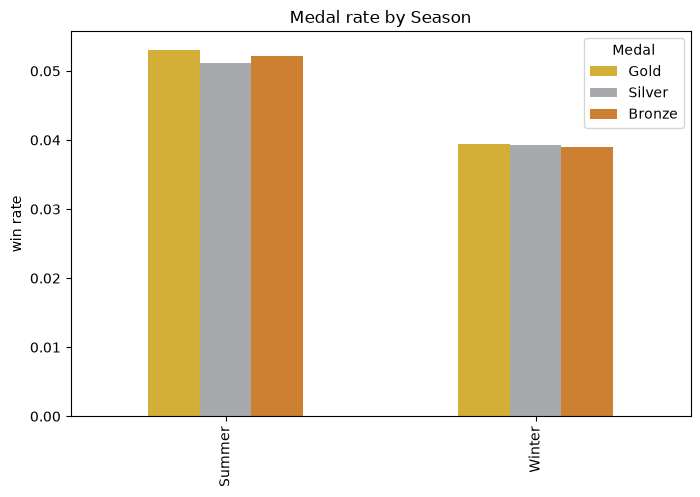

In [32]:

for i in ['Sex', 'Age_Group', 'Height_Group', 'Weight_Group', 'Season']:
    rates = pd.crosstab(df[i], df['Medal'], normalize='index')[['Gold', 'Silver', 'Bronze']]
    rates.plot(kind='bar', color=['#D4AF37', '#A8A9AD', '#CD7F32'], figsize=(8, 5),
               title=f'Medal rate by {i}', xlabel='', ylabel='win rate')


---

## Summary
__Summarizing the key insights from the analysis__

**Note**: _Use Bullet Points_

    ...

- The overall win rate is 14.9%.
- Among the 18 sports with more than 5,000 records, win rate ranges from 4.9% (Alpine Skiing) to 28.7% (Hockey), a nearly 6x gap.
- The top sports (Hockey, Rowing, Ice Hockey, Football) are all team sports, where one medal counts for every player on the roster.
- Summer Games win rate (about 15.6%) is higher than Winter (about 11.8%).
- Sex barely matters: about 15.2% for women vs 14.8% for men, and Gold, Silver and Bronze are each about 5% for both.
- Age peaks at 26-30 and is lowest for under 18 and 51+.
- Taller and heavier athletes win more often, but this probably reflects the sports they compete in rather than size itself.
- Early Games had very high win rates (about 46% in the 1890s) because fields were tiny, compared with about 14% in modern decades.

## Recommendations/Conclusion
**Note**: _Use Bullet Points_

    ...

- Medal chances depend heavily on the sport, not only on the athlete.
- Team medals inflate win rates in team sports, so they are not directly comparable with individual sports.
- Sex does not change the chance of winning or the type of medal.
- Old win rates from the early Games should not be used as a benchmark for today.
- Any judgement of sports or athlete development should account for competition size and team versus individual medals.